In [3]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

In [4]:
df = pd.read_csv('course_lead_scoring_2026.csv')

In [ ]:
df.head()

In [ ]:
print(df.isnull().sum())


In [8]:
# Identify categorical and numerical columns
categorical = df.select_dtypes(include=["object"]).columns
numerical = df.select_dtypes(include=["number"]).columns.drop("converted")

In [ ]:
# Fill missing values
df[categorical] = df[categorical].fillna("NA") # yes or no data is categorical, so we can fill missing values with "NA"
df[numerical] = df[numerical].fillna(0.0) # numerical data can be filled with 0.0

In [ ]:
# Confirm no missing values remain
print("\nMissing values after cleaning:")
print(df.isnull().sum())


In [11]:
# Split data exactly as instructed
df_full_train, df_test = train_test_split(
    df, test_size=0.2, random_state=1
)

df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [12]:
# Reset indices
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

QUESTION 1

In [14]:
from sklearn.metrics import roc_auc_score

# Define target
y_train = df_train["converted"]

# Numerical features
features = [
    "lead_score",
    "number_of_courses_viewed",
    "interaction_count",
    "annual_income"
]

# Calculate AUC for each feature
for feature in features:
    auc = roc_auc_score(y_train, df_train[feature])

    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[feature])

    print(f"{feature}: {auc:.4f}")

lead_score: 0.7882
number_of_courses_viewed: 0.7230
interaction_count: 0.7649
annual_income: 0.6082


QUESTION 2

In [15]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

# Separate features from target
X_train_df = df_train.drop(columns=["converted"])
X_val_df = df_val.drop(columns=["converted"])

y_train = df_train["converted"]
y_val = df_val["converted"]

# Convert features into dictionaries
train_dicts = X_train_df.to_dict(orient="records")
val_dicts = X_val_df.to_dict(orient="records")

# Apply one-hot encoding
dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

# Train logistic regression
model = LogisticRegression(
    solver="liblinear",
    C=1.0,
    max_iter=1000
)

model.fit(X_train, y_train)

# Predict probability of conversion
y_val_pred = model.predict_proba(X_val)[:, 1]

# Calculate validation AUC
auc = roc_auc_score(y_val, y_val_pred)

print("Validation AUC:", round(auc, 3))

Validation AUC: 0.732


QUESTION 3

Best threshold: 0.63
Precision: 0.7328
Recall: 0.7253
Difference: 0.0075


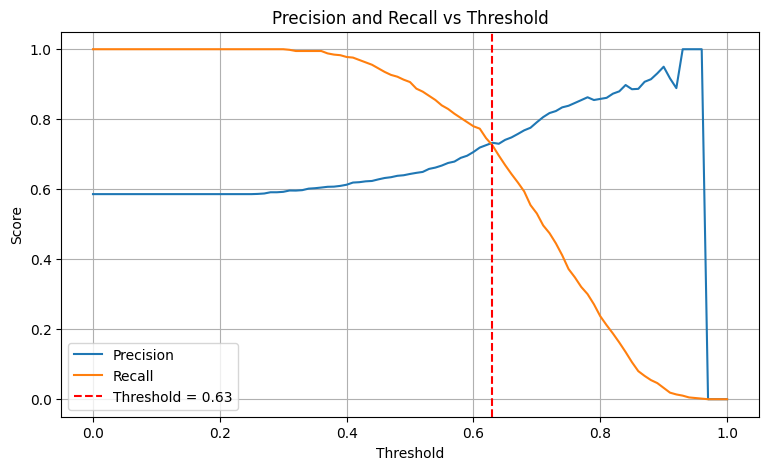

In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score

thresholds = np.arange(0.0, 1.01, 0.01)

precisions = []
recalls = []

for t in thresholds:
    # Convert predicted probabilities to 0 or 1
    y_pred = y_val_pred >= t

    # Calculate precision and recall
    p = precision_score(y_val, y_pred, zero_division=0)
    r = recall_score(y_val, y_pred, zero_division=0)

    precisions.append(p)
    recalls.append(r)

# Store results
results = pd.DataFrame({
    "threshold": thresholds,
    "precision": precisions,
    "recall": recalls
})

# Exclude cases where both metrics are zero
valid = results[
    (results["precision"] != 0) |
    (results["recall"] != 0)
].copy()

# Calculate absolute difference
valid["difference"] = abs(
    valid["precision"] - valid["recall"]
)

# Find the threshold with the smallest difference
best = valid.loc[valid["difference"].idxmin()]

print("Best threshold:", round(best["threshold"], 2))
print("Precision:", round(best["precision"], 4))
print("Recall:", round(best["recall"], 4))
print("Difference:", round(best["difference"], 4))

# Plot both curves
plt.figure(figsize=(9, 5))

plt.plot(thresholds, precisions, label="Precision")
plt.plot(thresholds, recalls, label="Recall")

plt.axvline(
    best["threshold"],
    color="red",
    linestyle="--",
    label=f'Threshold = {best["threshold"]:.2f}'
)

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall vs Threshold")
plt.legend()
plt.grid()
plt.show()

QUESTION 4

Best threshold: 0.41
Maximum F1: 0.7576

F1 at the answer options:
 threshold       f1
      0.21 0.738966
      0.41 0.757616
      0.61 0.745066
      0.81 0.339726


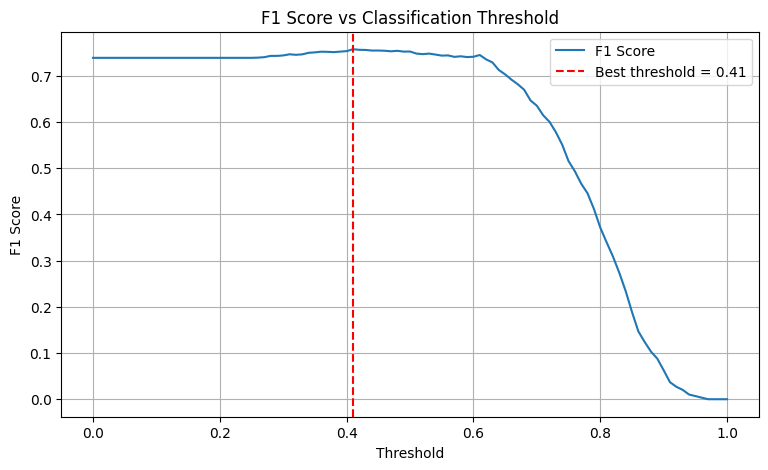

In [17]:
# Calculate F1 for each threshold
results["f1"] = (
    2 * results["precision"] * results["recall"]
    / (results["precision"] + results["recall"]).replace(0, np.nan)
).fillna(0)

# Find the threshold with the highest F1
best_f1 = results.loc[results["f1"].idxmax()]

print("Best threshold:", round(best_f1["threshold"], 2))
print("Maximum F1:", round(best_f1["f1"], 4))

# Compare the answer options
options = [0.21, 0.41, 0.61, 0.81]

print("\nF1 at the answer options:")
print(
    results[
        results["threshold"].round(2).isin(options)
    ][["threshold", "f1"]].to_string(index=False)
)

# Plot F1 against threshold
plt.figure(figsize=(9, 5))
plt.plot(results["threshold"], results["f1"], label="F1 Score")

plt.axvline(
    best_f1["threshold"],
    color="red",
    linestyle="--",
    label=f'Best threshold = {best_f1["threshold"]:.2f}'
)

plt.xlabel("Threshold")
plt.ylabel("F1 Score")
plt.title("F1 Score vs Classification Threshold")
plt.legend()
plt.grid()
plt.show()

QUESTION 5 

In [18]:
from sklearn.model_selection import KFold

# Define 5-fold cross-validation
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):

    # Split into training and validation folds
    df_train_fold = df_full_train.iloc[train_idx]
    df_val_fold = df_full_train.iloc[val_idx]

    # Separate features and target
    y_train_fold = df_train_fold["converted"]
    y_val_fold = df_val_fold["converted"]

    train_dicts = df_train_fold.drop(
        columns=["converted"]
    ).to_dict(orient="records")

    val_dicts = df_val_fold.drop(
        columns=["converted"]
    ).to_dict(orient="records")

    # One-hot encoding
    dv_fold = DictVectorizer(sparse=False)

    X_train_fold = dv_fold.fit_transform(train_dicts)
    X_val_fold = dv_fold.transform(val_dicts)

    # Train logistic regression
    model_fold = LogisticRegression(
        solver="liblinear",
        C=1.0,
        max_iter=1000
    )

    model_fold.fit(X_train_fold, y_train_fold)

    # Predict probabilities
    y_pred_fold = model_fold.predict_proba(X_val_fold)[:, 1]

    # Calculate AUC
    auc = roc_auc_score(y_val_fold, y_pred_fold)

    scores.append(auc)

# Display results
print("AUC scores:", scores)
print("Mean AUC:", round(np.mean(scores), 4))
print("Standard deviation:", round(np.std(scores), 3))

AUC scores: [0.7305601027122453, 0.7295726148196622, 0.7363428071259397, 0.7412454717957564, 0.7209138590326581]
Mean AUC: 0.7317
Standard deviation: 0.007


QUESTION 6

In [19]:
C_values = [0.000001, 0.001, 1]

results_q6 = []

for C in C_values:
    kfold = KFold(
        n_splits=5,
        shuffle=True,
        random_state=1
    )

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):

        df_train_fold = df_full_train.iloc[train_idx]
        df_val_fold = df_full_train.iloc[val_idx]

        y_train_fold = df_train_fold["converted"]
        y_val_fold = df_val_fold["converted"]

        train_dicts = df_train_fold.drop(
            columns=["converted"]
        ).to_dict(orient="records")

        val_dicts = df_val_fold.drop(
            columns=["converted"]
        ).to_dict(orient="records")

        dv_fold = DictVectorizer(sparse=False)

        X_train_fold = dv_fold.fit_transform(train_dicts)
        X_val_fold = dv_fold.transform(val_dicts)

        model_fold = LogisticRegression(
            solver="liblinear",
            C=C,
            max_iter=1000
        )

        model_fold.fit(X_train_fold, y_train_fold)

        y_pred_fold = model_fold.predict_proba(
            X_val_fold
        )[:, 1]

        auc = roc_auc_score(y_val_fold, y_pred_fold)

        scores.append(auc)

    mean_auc = round(np.mean(scores), 3)
    std_auc = round(np.std(scores), 3)

    results_q6.append({
        "C": C,
        "mean_auc": mean_auc,
        "std_auc": std_auc
    })

    print(
        f"C={C}, Mean AUC={mean_auc:.3f}, "
        f"Std={std_auc:.3f}"
    )

# Select best C:
# highest rounded mean, then lowest rounded std,
# then smallest C
best = sorted(
    results_q6,
    key=lambda x: (
        -x["mean_auc"],
        x["std_auc"],
        x["C"]
    )
)[0]

print("\nBest C:", best["C"])

C=1e-06, Mean AUC=0.617, Std=0.019
C=0.001, Mean AUC=0.749, Std=0.010
C=1, Mean AUC=0.732, Std=0.007

Best C: 0.001
